In [1]:
import pandas as pd
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, brier_score_loss
import time
from sklearn.preprocessing import StandardScaler

In [2]:
# Load the Parkinson's dataset
file_path = 'assessment-item1\parkinsons_data-VOICE-features.xlsx'
parkinsons_df = pd.read_excel(file_path)
print(parkinsons_df.head())
print(parkinsons_df.info())

             name  MDVP:Fo(Hz)  MDVP:Fhi(Hz)  MDVP:Flo(Hz)  MDVP:Jitter(%)  \
0  phon_R01_S01_1      119.992       157.302        74.997         0.00784   
1  phon_R01_S01_2      122.400       148.650       113.819         0.00968   
2  phon_R01_S01_3      116.682       131.111       111.555         0.01050   
3  phon_R01_S01_4      116.676       137.871       111.366         0.00997   
4  phon_R01_S01_5      116.014       141.781       110.655         0.01284   

   MDVP:Jitter(Abs)  MDVP:RAP  MDVP:PPQ  Jitter:DDP  MDVP:Shimmer  ...  \
0           0.00007   0.00370   0.00554     0.01109       0.04374  ...   
1           0.00008   0.00465   0.00696     0.01394       0.06134  ...   
2           0.00009   0.00544   0.00781     0.01633       0.05233  ...   
3           0.00009   0.00502   0.00698     0.01505       0.05492  ...   
4           0.00011   0.00655   0.00908     0.01966       0.06425  ...   

   Shimmer:DDA      NHR     HNR  status      RPDE       DFA   spread1  \
0      0.0654

### **Drop Irrelevant Columns:**
parkinsons_df.drop(columns=['name'], errors='ignore') removes the name column from the dataset.

### **Separate Features (X) and Target Variable (y):**
#### X = parkinsons_df.drop(columns=['status']):

X holds all the features (input variables) used to train the model. This is done by dropping the status column from the dataset.

X includes all the voice-related attributes, such as MDVP:Fo(Hz), MDVP:Fhi(Hz), which the model will use to determine if a person has Parkinson’s.

#### y = parkinsons_df['status']:
y is our target variable, containing the status column, which represents the condition we aim to predict.

The status column is typically binary (0 for no Parkinson’s, 1 for Parkinson’s), making it suitable for classification.


In [3]:
# Drop irrelevant columns and prepare features and target variable
parkinsons_df = parkinsons_df.drop(columns=['name'], errors='ignore')
X = parkinsons_df.drop(columns=['status'])
y = parkinsons_df['status']


In [4]:
# Apply scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
# # Split data into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, stratify=y, random_state=42)


In [6]:
# # Define the kernel for Gaussian Process (using RBF kernel with a constant term)
#kernel = C(1.0) * RBF(length_scale=1.0)
# Define the Gaussian Process Classifier with tuned kernel parameters
# Adjusted length_scale and constant kernel value
kernel = C(1.5, (1e-3, 1e1)) * RBF(length_scale=1.5, length_scale_bounds=(1e-2, 1e2))

In [7]:
# Initialize the Gaussian Process Classifier with the specified kernel
gpc = GaussianProcessClassifier(kernel=kernel, random_state=42)

In [8]:
# Train the model and record training time
start_train_time = time.time()
gpc.fit(X_train, y_train)
train_time = time.time() - start_train_time

# Predict probabilities for the test set and record testing time
start_test_time = time.time()
y_proba = gpc.predict_proba(X_test)[:, 1]  # Probabilities for class 1 (Parkinson's)
y_pred = gpc.predict(X_test)
test_time = time.time() - start_test_time

# Calculate Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_proba)
kl_divergence = log_loss(y_test, y_proba)  # Log Loss approximates KL Divergence in binary classification
brier_score = brier_score_loss(y_test, y_proba)

c:\Users\msi 1\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [9]:
# Print Results
print("Model Evaluation Metrics for Gaussian Process Classifier:")
print(f"Accuracy: {accuracy:.4f}")
print(f"AUC: {auc_score:.4f}")
print(f"Kullback-Leibler Divergence (Log Loss): {kl_divergence:.4f}")
print(f"Brier Score: {brier_score:.4f}")
print(f"Training Time: {train_time:.4f} seconds")
print(f"Testing Time: {test_time:.4f} seconds")

Model Evaluation Metrics for Gaussian Process Classifier:
Accuracy: 0.9231
AUC: 0.9655
Kullback-Leibler Divergence (Log Loss): 0.2835
Brier Score: 0.0777
Training Time: 0.2374 seconds
Testing Time: 0.0040 seconds


In [10]:
import numpy as np

In [11]:
# Define the function to ensure compatibility of query data with X
def query_proba(query_data, X, scaler, gpc):
    # Convert query_data to DataFrame
    query_df = pd.DataFrame([query_data])
    
    # Add any missing columns with the mean values from X
    for col in X.columns:
        if col not in query_df.columns:
            query_df[col] = X[col].mean()
    
    # Ensure the columns in the same order as X
    query_df = query_df[X.columns]
    
    # Apply scaling
    query_df_scaled = scaler.transform(query_df)
    
    # Predict probabilities
    query_proba = gpc.predict_proba(query_df_scaled)
    return query_proba[0]

# Query 1
query_1 = {
    'MDVP:Fo(Hz)': 197.076, 
    'MDVP:Fhi(Hz)': 206.896, 
    'MDVP:Flo(Hz)': 192.055,
    'MDVP:Jitter(%)': 0.00289, 
    'MDVP:Jitter(Abs)': 0.00001, 
    'MDVP:RAP': 0.00166,
    'MDVP:PPQ': 0.00168, 
    'Jitter:DDP': 0.00498, 
    'MDVP:Shimmer': 0.01098,
    'MDVP:Shimmer(dB)': 0.097, 
    'Shimmer:APQ3': 0.00563, 
    'Shimmer:APQ5': 0.0068,
    'MDVP:APQ': 0.00802, 
    'Shimmer:DDA': 0.01689, 
    'NHR': 0.00339, 
    'HNR': 26.775
}
proba_query_1 = query_proba(query_1, X, scaler, gpc)
print(f"Probability of status=0 (no Parkinson's) for Query 1: {proba_query_1[0]:.4f}")
print(f"Probability of status=1 (Parkinson's) for Query 1: {proba_query_1[1]:.4f}")

# Query 2
query_2 = {
    'MDVP:Fo(Hz)': 162.568, 
    'MDVP:Fhi(Hz)': 198.346, 
    'MDVP:Flo(Hz)': 77.63,
    'MDVP:Jitter(%)': 0.00502, 
    'MDVP:Jitter(Abs)': 0.00003, 
    'MDVP:RAP': 0.0028,
    'MDVP:PPQ': 0.00253, 
    'Jitter:DDP': 0.00841, 
    'MDVP:Shimmer': 0.01791,
    'MDVP:Shimmer(dB)': 0.168, 
    'Shimmer:APQ3': 0.00793, 
    'Shimmer:APQ5': 0.01057,
    'MDVP:APQ': 0.01799, 
    'Shimmer:DDA': 0.0238, 
    'NHR': 0.0117, 
    'HNR': 25.678
}
proba_query_2 = query_proba(query_2, X, scaler, gpc)
print(f"Probability of status=0 (no Parkinson's) for Query 2: {proba_query_2[0]:.4f}")
print(f"Probability of status=1 (Parkinson's) for Query 2: {proba_query_2[1]:.4f}")

Probability of status=0 (no Parkinson's) for Query 1: 0.2124
Probability of status=1 (Parkinson's) for Query 1: 0.7876
Probability of status=0 (no Parkinson's) for Query 2: 0.0882
Probability of status=1 (Parkinson's) for Query 2: 0.9118


In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc,
    precision_recall_curve, PrecisionRecallDisplay
)
import numpy as np
from sklearn.calibration import calibration_curve

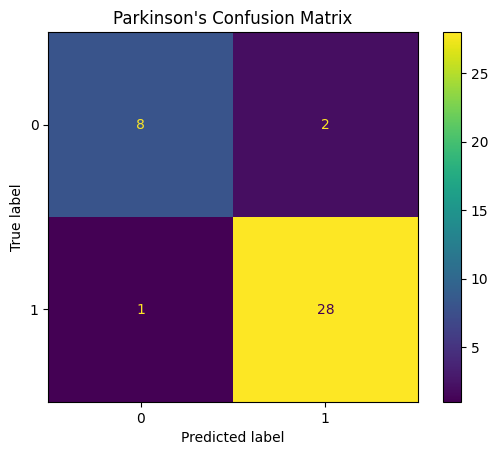

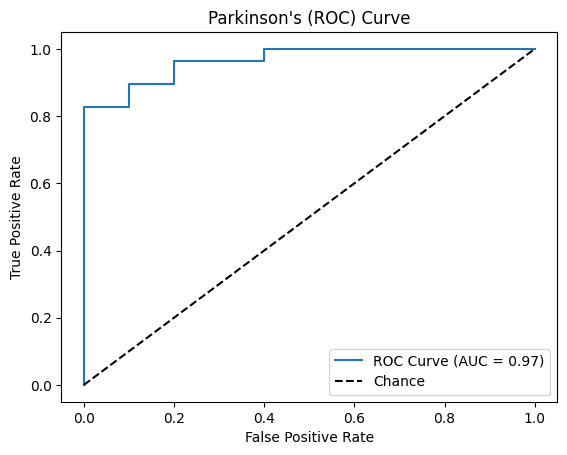

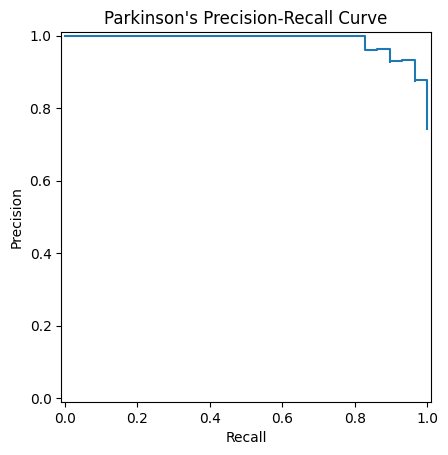

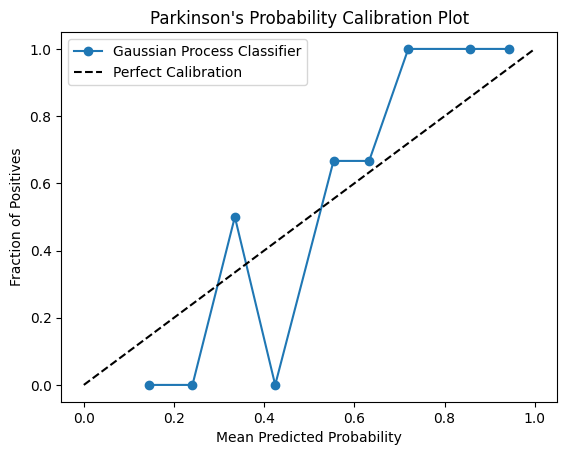

In [16]:
# Assuming y_test contains the true labels and y_proba contains the predicted probabilities
y_pred = (y_proba >= 0.5).astype(int)  # Classify based on probability threshold 0.5

# 1. Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(conf_matrix).plot()
plt.title("Parkinson's Confusion Matrix")
plt.show()

# 2. ROC Curve with AUC
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Parkinson's (ROC) Curve")
plt.legend()
plt.show()

# 3. Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_proba)
PrecisionRecallDisplay(precision=precision, recall=recall).plot()
plt.title("Parkinson's Precision-Recall Curve")
plt.show()

# 4. Probability Calibration Plot
prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10)
plt.figure()
plt.plot(prob_pred, prob_true, marker='o', label="Gaussian Process Classifier")
plt.plot([0, 1], [0, 1], 'k--', label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Parkinson's Probability Calibration Plot")
plt.legend()
plt.show()


In [12]:
# # Define the feature values for Query 3 as a dictionary
# query_data = {
#     'MDVP:Fo(Hz)': 197.076,
#     'MDVP:Fhi(Hz)': 206.896,
#     'MDVP:Flo(Hz)': 192.055,
#     'MDVP:Jitter(%)': 0.00289,
#     'MDVP:Jitter(Abs)': 0.00001,
#     'MDVP:RAP': 0.00166,
#     'MDVP:PPQ': 0.00168,
#     'Jitter:DDP': 0.00498,
#     'MDVP:Shimmer': 0.01098,
#     'MDVP:Shimmer(dB)': 0.097,
#     'Shimmer:APQ3': 0.00563,
#     'Shimmer:APQ5': 0.0068,
#     'MDVP:APQ': 0.00802,
#     'Shimmer:DDA': 0.01689,
#     'NHR': 0.00339,
#     'HNR': 26.775
# }

# # Convert query data to DataFrame
# query_df = pd.DataFrame([query_data])

# # Add any missing columns from the training data, filling with mean values
# missing_cols = [col for col in X.columns if col not in query_df.columns]
# for col in missing_cols:
#     query_df[col] = X[col].mean()

# # Ensure columns in query_df are in the same order as training data
# query_df = query_df[X.columns]

# # Use the trained Gaussian Process Classifier to predict probabilities
# query_proba = gpc.predict_proba(query_df)

# # Extract the probability for status=0 (no Parkinson's) and status=1 (Parkinson's)
# status_0_proba = query_proba[0][0]  # Probability of status=0
# status_1_proba = query_proba[0][1]  # Probability of status=1

# # Print the results
# print(f"Probability of status=0 (no Parkinson's) given the evidence: {status_0_proba:.4f}")
# print(f"Probability of status=1 (Parkinson's) given the evidence: {status_1_proba:.4f}")

In [13]:
# # Define the feature values for Query 4 as a dictionary
# query_data = {
#     'MDVP:Fo(Hz)': 162.568,
#     'MDVP:Fhi(Hz)': 198.346,
#     'MDVP:Flo(Hz)': 77.63,
#     'MDVP:Jitter(%)': 0.00502,
#     'MDVP:Jitter(Abs)': 0.00003,
#     'MDVP:RAP': 0.0028,
#     'MDVP:PPQ': 0.00253,
#     'Jitter:DDP': 0.00841,
#     'MDVP:Shimmer': 0.01791,
#     'MDVP:Shimmer(dB)': 0.168,
#     'Shimmer:APQ3': 0.00793,
#     'Shimmer:APQ5': 0.01057,
#     'MDVP:APQ': 0.01799,
#     'Shimmer:DDA': 0.0238,
#     'NHR': 0.0117,
#     'HNR': 25.678
# }

# # Convert query data to DataFrame
# query_df = pd.DataFrame([query_data])

# # Add any missing columns from the training data, filling with mean values
# missing_cols = [col for col in X.columns if col not in query_df.columns]
# for col in missing_cols:
#     query_df[col] = X[col].mean()

# # Ensure columns in query_df are in the same order as training data
# query_df = query_df[X.columns]

# # Use the trained Gaussian Process Classifier to predict probabilities
# query_proba = gpc.predict_proba(query_df)

# # Extract the probability for status=1 (Parkinson's)
# status_0_proba = query_proba[0][0]
# status_1_proba = query_proba[0][1]  # Probability of status=1

# # Print the result
# print(f"Probability of status=0 (no Parkinson's) given the evidence: {status_0_proba:.4f}")
# print(f"Probability of status=1 (Parkinson's) given the evidence: {status_1_proba:.4f}")